# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()

## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [3]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [4]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [5]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [6]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

## Task Solution

### Load `bert-base-uncased`

We load the base BERT model with `attn_implementation="eager"` so that it can return the attention weights.

In [7]:
from transformers import AutoTokenizer, AutoModel
import torch

bert_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)

bert_model = AutoModel.from_pretrained(bert_name, attn_implementation="eager")
bert_model.eval()

print("Model loaded:", bert_name)

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded: bert-base-uncased


### 1. Number of Transformer layers and attention heads per layer

In [8]:
num_layers = bert_model.config.num_hidden_layers
num_heads = bert_model.config.num_attention_heads

print("Transformer layers:", num_layers)
print("Attention heads per layer:", num_heads)
print("Hidden size:", bert_model.config.hidden_size)

Transformer layers: 12
Attention heads per layer: 12
Hidden size: 768


### 2. Total number of attention heads across all layers

In [9]:
total_heads = num_layers * num_heads

print(f"Total attention heads = {num_layers} layers x {num_heads} heads = {total_heads}")

Total attention heads = 12 layers x 12 heads = 144


### 3. Attention weights from the third layer, second head

Python indexes from 0, so the **third layer** is `attentions[2]` and the **second head** is index `1`.

In [10]:
task_sentence = "Transformers use self-attention to understand language."

task_inputs = bert_tokenizer(task_sentence, return_tensors="pt")
task_tokens = bert_tokenizer.convert_ids_to_tokens(task_inputs["input_ids"][0])

with torch.no_grad():
    bert_outputs = bert_model(**task_inputs, output_attentions=True)

print("Number of attention tensors (one per layer):", len(bert_outputs.attentions))
print("Shape of one layer's attention:", tuple(bert_outputs.attentions[0].shape))

layer_index = 2
head_index = 1
attention_l3_h2 = bert_outputs.attentions[layer_index][0, head_index]

print()
print("Tokens:", task_tokens)
print("Attention shape (layer 3, head 2):", tuple(attention_l3_h2.shape))
print("Each row sums to 1:", torch.allclose(attention_l3_h2.sum(dim=-1), torch.ones(len(task_tokens))))

Number of attention tensors (one per layer): 12
Shape of one layer's attention: (1, 12, 11, 11)

Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Attention shape (layer 3, head 2): (11, 11)
Each row sums to 1: True


In [11]:
import pandas as pd

attention_df = pd.DataFrame(attention_l3_h2.numpy().round(3), index=task_tokens, columns=task_tokens)
attention_df

,[CLS],transformers,use,self,-,attention,to,understand,language,.,[SEP]
[CLS],0.732,0.008,0.011,0.006,0.017,0.007,0.010,0.012,0.006,0.039,0.155
transformers,0.889,0.005,0.034,0.000,0.003,0.005,0.001,0.001,0.000,0.005,0.057
use,0.143,0.569,0.005,0.035,0.041,0.068,0.090,0.000,0.005,0.009,0.034
self,0.340,0.073,0.002,0.000,0.202,0.081,0.064,0.026,0.002,0.028,0.183
-,0.143,0.070,0.071,0.639,0.012,0.013,0.003,0.003,0.014,0.009,0.022
attention,0.113,0.545,0.012,0.020,0.111,0.010,0.072,0.000,0.000,0.016,0.100
to,0.084,0.022,0.622,0.008,0.009,0.194,0.011,0.007,0.001,0.014,0.027
understand,0.434,0.005,0.002,0.022,0.012,0.003,0.330,0.002,0.055,0.053,0.082
language,0.051,0.001,0.429,0.002,0.004,0.001,0.005,0.398,0.006,0.041,0.062
.,0.658,0.006,0.003,0.001,0.004,0.003,0.009,0.038,0.046,0.073,0.159


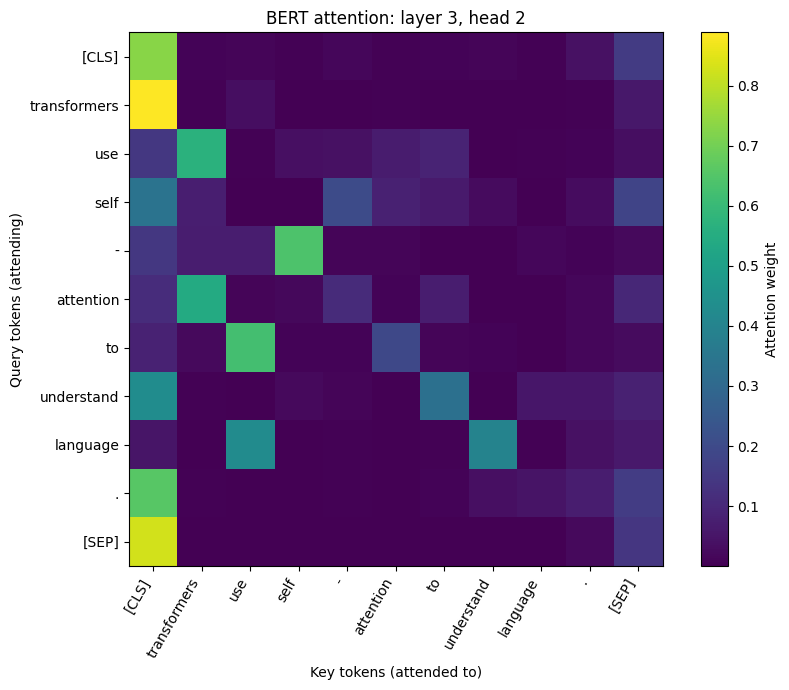

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(attention_l3_h2.numpy(), cmap="viridis")

ax.set_xticks(range(len(task_tokens)))
ax.set_yticks(range(len(task_tokens)))
ax.set_xticklabels(task_tokens, rotation=60, ha="right")
ax.set_yticklabels(task_tokens)

ax.set_xlabel("Key tokens (attended to)")
ax.set_ylabel("Query tokens (attending)")
ax.set_title("BERT attention: layer 3, head 2")
fig.colorbar(im, ax=ax, label="Attention weight")

plt.tight_layout()
plt.show()

### 4. What the rows and columns of the attention matrix represent

The matrix has shape `(seq_len, seq_len)`. There is one row and one column for every token, including `[CLS]` and `[SEP]`.

- **Rows are the query tokens.** Row *i* belongs to the token that is gathering information, and holds that token's attention over the whole sentence.
- **Columns are the key tokens.** Column *j* belongs to the token being looked at.
- **Cell (i, j)** says how much token *i* attends to token *j* when this head builds token *i*'s new contextual representation.
- **Each row sums to 1** because softmax is applied over the columns. So each row is a probability distribution over all tokens. The code above checks this.
- The matrix is **not symmetric**. How much token *i* attends to *j* can differ from how much *j* attends to *i*.

Each head in each layer learns its own pattern. Some heads focus on the previous or next token, some on the special `[CLS]`/`[SEP]` tokens, and some on related words. This is why we pick one specific layer and head to look at.